# Labb 3 – ALM-analysis

## Imports

Inherited parameters from CA2 lives in `congig.py`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import config
from alm import prepare_alm

# 1. The state model

Implement the state model for the policy and plot the populations (PP, PO, TR, DE) for each period 50 years
(600 months) into the future. Use the area plot to visualize the size of the populations over time.

In [2]:
from state_model import state_model

pop_pp, pop_po, pop_tr, pop_de, t_pp_de, t_po_de, t_pp_tr, t_pp_po = state_model(
    n_months=600
)

total_population = pop_pp + pop_po + pop_tr + pop_de

#### Area chart

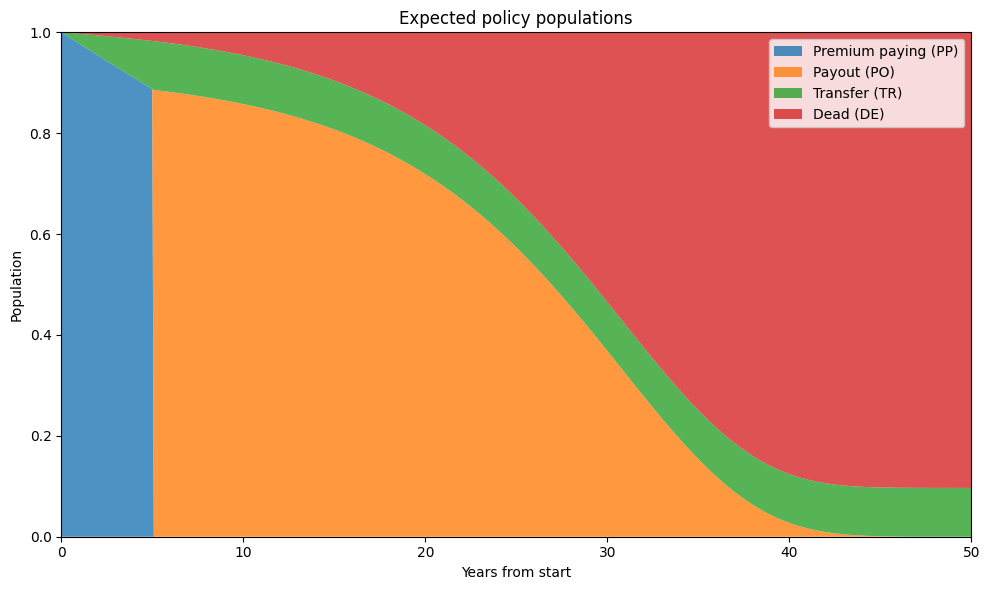

In [3]:
years = np.arange(len(pop_pp)) / 12

fig, ax = plt.subplots(figsize=(10, 6))

ax.stackplot(
    years,
    pop_pp, pop_po, pop_tr, pop_de,
    labels=["Premium paying (PP)", "Payout (PO)", "Transfer (TR)", "Dead (DE)"],
    alpha=0.8
)

ax.set_xlabel("Years from start")
ax.set_ylabel("Population")
ax.set_title("Expected policy populations")
ax.set_xlim(0, 50)
ax.set_ylim(0, 1)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

# 2. The ALM-model

Implement an ALM-model that in each scenario, and in each time period, calculates the:
• expected 1st-order reserve (G),
• expected 2nd-order reserve (V),
• value of the assets,
• technical provisions (only BE) and basic own funds (BOF)

In [4]:
one_scenario = pd.read_csv("OneScenario.csv")

alm_inputs = prepare_alm(one_scenario, n_months=360)


#### Model preparations

`prepare_alm` prepares the stock returns and initial portfolio. It also calls
`prepare_first_order_policy` in `policy.py` to calculate the guaranteed pension,
reserve, populations and first-order cash flows up to age 120.

The simulation covers 360 months, but the policy cash flows cover 720 months
so that later payments can be included in BE.

In [5]:
print("Initial stock holdings:", alm_inputs["initial_holdings"])
print("Initial asset value:", alm_inputs["initial_holdings"].sum())
print(f"Guaranteed yearly pension: {alm_inputs['policy']['b']:.4f}")
print("Initial expected first-order reserve:", alm_inputs["policy"]["expected_G"][0])


Initial stock holdings: [210000. 210000. 210000. 210000. 210000. 210000. 210000. 210000. 210000.
 210000.]
Initial asset value: 2100000.0
Guaranteed yearly pension: 164404.8790
Initial expected first-order reserve: 2000000.0


In [6]:
from alm import run_alm

alm_results = run_alm(one_scenario, n_months=360)
alm_results.head()

,Period,Expected G,Expected V,Assets,BE,BOF
0,0,2.000000e+06,2.100000e+06,2.100000e+06,1.671089e+06,428911.451758
1,1,2.009913e+06,2.114988e+06,2.115005e+06,1.681827e+06,433177.581221
2,2,2.019807e+06,2.129992e+06,2.130027e+06,1.692557e+06,437469.824447
3,3,2.029682e+06,2.145013e+06,2.145065e+06,1.703277e+06,441788.212277
4,4,2.039537e+06,2.160050e+06,2.160121e+06,1.713988e+06,446132.775658


#### a) Plot the evolution of the expected reserves, assets, and BE in the same plot for 30 years.

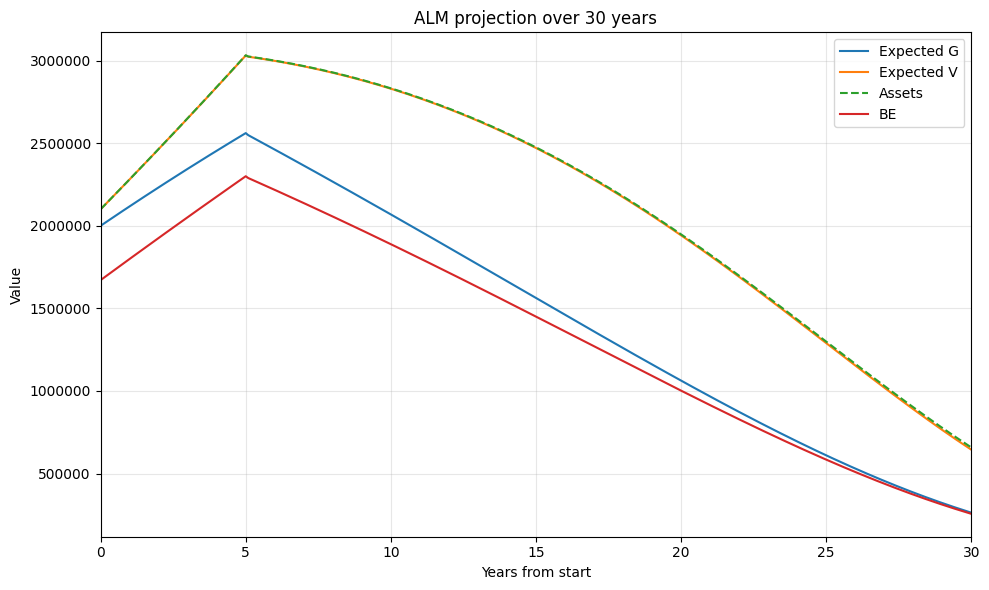

In [7]:
years = alm_results["Period"] / 12

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(years, alm_results["Expected G"], label="Expected G")
ax.plot(years, alm_results["Expected V"], label="Expected V")
ax.plot(years, alm_results["Assets"], label="Assets", linestyle="--")
ax.plot(years, alm_results["BE"], label="BE")

ax.set_xlabel("Years from start")
ax.set_ylabel("Value")
ax.set_title("ALM projection over 30 years")
ax.set_xlim(0, 30)
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### b) Include a table with the values of the above items at every fifth year.

In [8]:
table = alm_results.loc[alm_results["Period"] % 60 == 0,
                        ["Period", "Expected G", "Expected V", "Assets", "BE"]
                        ].copy() # %60 => var 5e år, 5år =6mån

table["Period"] = (table["Period"] // 12).astype(int)
table = table.rename(columns={"Period": "Year"})

display(table.round(2).reset_index(drop=True))

,Year,Expected G,Expected V,Assets,BE
0,0,2000000.00,2100000.00,2100000.00,1671088.55
1,5,2560874.92,3030534.41,3032013.38,2299806.21
2,10,2068542.07,2829534.52,2831884.11,1888349.40
3,15,1562687.29,2470778.26,2474507.13,1450100.51
4,20,1062689.71,1942167.89,1948088.74,1001942.71
5,25,610320.10,1289675.32,1298874.38,584397.40
6,30,263356.40,644720.70,658346.48,256395.72


#### c) Calculate $SCR_{longevity}$ according to the Solvency 2 standard model.


In [9]:
from policy import prepare_first_order_policy
from valuation import calculate_be

stressed_policy = prepare_first_order_policy(mortality_factor=0.8)
stressed_cashflow = stressed_policy["first_order_cashflow"]

BE_stress = calculate_be(one_scenario.iloc[:1], stressed_cashflow)[0]

BE_base = alm_results["BE"].iloc[0]
SCR_longevity = BE_base - BE_stress

print(f"Base BE       Stressed BE   SCR")
print(f"{BE_base:,.2f}  {BE_stress:,.2f}  {SCR_longevity:,.2f}")

Base BE       Stressed BE   SCR
1,671,088.55  1,774,925.62  -103,837.08


# Estimation of risk capital 
Use simulation to estimate the SCR, which we here take as the 1-year VaR for the loss in basic own funds at
the 95% confidence leveland plot also the empirical distribution of $BOF_1$ as a histogram with fixed x-limits: (-500 000, 3 000 000) and 50 bins.



In [10]:
scenario_file = pd.read_csv("ScenarioFile.csv")
scenario_1 = scenario_file.loc[scenario_file["Scenario"]==1]
print(scenario_1.head())
print(scenario_1.shape)

   Unnamed: 0  Scenario  Period          BA         CAT         KO  \
0           0         1       0  218.500000  573.882996  68.734924   
1           1         1       1  201.806264  511.631351  67.604561   
2           2         1       2  167.402263  430.475457  64.566459   
3           3         1       3  153.857659  470.627803  70.213817   
4           4         1       4  160.816784  506.729865  68.129273   

          DIS         JPM         MMM        MSFT  ...          Z5  \
0  113.917114  318.891754  158.928787  484.406830  ...  100.000000   
1   84.400383  261.155980  162.942169  440.417540  ...  104.353594   
2   73.576724  215.484455  152.543545  436.448352  ...  108.231568   
3   75.248426  202.368262  160.665228  488.150585  ...  108.715996   
4   73.558024  231.343360  167.859987  513.839388  ...  109.517393   

          Z10         Z15         Z20         Z30        Y5       Y10  \
0  100.000000  100.000000  100.000000  100.000000  0.036592  0.042127   
1  106.78562

#### a) BH(0/100), where you are entirely invested in the Z15 bond.

In [ ]:
bh_zcb15_result = run_alm(
    scenario=scenario_1,
    n_months=12,
    asset_columns=["Z15"]
)

#### b) BH(50/50), where the initial stock investment is equally distributed among the ten stocks and the bond investment is entirely invested in the Z5 bond.